# Answering questions with pandas: Completed activity


## Purpose and setup

Read and write pandas pipelines, summarize groups, attach group references to
talks, and make plots. Equivalent code can be correct when it answers the same
question. Every claim below describes the supplied dataset.

Run this file from its own directory in Positron. The relative path reflects
the file's location inside `activity/`.



In [1]:
import pandas as pd
import matplotlib.pyplot as plt

talks = pd.read_csv("../data/talks.csv")
talks.shape

794

14



One row represents one talk. The initial shape is `(794, 14)`.

## Checkpoint 0: Review familiar pipelines

### Decode the code

Before running, describe the question this code answers. Predict its type and
shape, and explain why sorting precedes `head(3)`.



In [2]:
decoded = (
    talks.loc[
        (talks["year"] == 2020)
        & (talks["session"] == "sunday-morning"),
        ["talk_name", "speaker", "num_words"]
    ]
    .sort_values("num_words", ascending=False)
    .head(3)
)
decoded

,talk_name,speaker,num_words
727,Hear Him,Russell M. Nelson,2591
497,“Let This House Be Built unto My Name”,David A. Bednar,1912
739,Let God Prevail,Russell M. Nelson,1858




The result is a three-row, three-column DataFrame containing the three Sunday
morning talks from 2020 with the largest word counts. Taking `head(3)` before
sorting would restrict the candidates before finding the largest counts.

### Construct the code

Find the three Saturday morning talks from 2019 or 2020 with the largest word
counts. Show the title, speaker, year, and word count.



In [3]:
review_mask = (
    talks["year"].between(2019, 2020)
    & (talks["session"] == "saturday-morning")
)

review_answer = (
    talks.loc[review_mask, ["talk_name", "speaker", "year", "num_words"]]
    .sort_values("num_words", ascending=False)
    .head(3)
)
review_answer

,talk_name,speaker,year,num_words
717,A Home Where the Spirit of the Lord Dwells,Henry B. Eyring,2019,2247
694,Shall We Not Go On in So Great a Cause?,M. Russell Ballard,2020,2234
19,Answers to Prayer,Brook P. Hales,2019,2141


In [4]:
review_checks = {
    "three_rows": len(review_answer) == 3,
    "allowed_years": review_answer["year"].isin([2019, 2020]).all(),
    "correct_session": talks.loc[review_answer.index, "session"].eq(
        "saturday-morning"
    ).all(),
    "decreasing_word_count": review_answer["num_words"].is_monotonic_decreasing,
}
review_checks

{'three_rows': True, 'allowed_years': np.True_, 'correct_session': np.True_, 'decreasing_word_count': True}



## Checkpoint 1: Predict aggregation and transformation

The following talks are invented to make the calculations visible.



In [5]:
toy = pd.DataFrame({
    "talk": list("ABCDEF"),
    "session": ["morning"] * 3 + ["afternoon"] * 3,
    "num_words": [1000, 2000, 3000, 1000, 1200, 1400],
})
toy

,talk,session,num_words
0,A,morning,1000
1,B,morning,2000
2,C,morning,3000
3,D,afternoon,1000
4,E,afternoon,1200
5,F,afternoon,1400




Predict how many rows remain after calculating session medians.



In [6]:
toy_summary = toy.groupby("session", as_index=False).agg(
    median_words=("num_words", "median")
)
toy_summary

,session,median_words
0,afternoon,1200.0
1,morning,2000.0




Two rows represent two sessions. The original talk identities are absent.

### Inspect the GroupBy object



In [7]:
grouped = toy.groupby("session")
print(type(grouped).__name__, grouped.ngroups)
grouped.indices

DataFrameGroupBy 2


{'afternoon': array([3, 4, 5]), 'morning': array([0, 1, 2])}



The mapping associates each group key with row positions: afternoon uses 3, 4,
and 5, while morning uses 0, 1, and 2. Creating a GroupBy specifies the grouping.
Inspection and calculations request the grouping work when they need it.



In [8]:
grouped.get_group("morning")

,talk,session,num_words
0,A,morning,1000
1,B,morning,2000
2,C,morning,3000


In [9]:
grouped.obj is toy, len(toy)

True

6



The GroupBy keeps the source object. Extracting a group leaves the original
six-row table intact. Selecting a column and requesting a reduction determines
what to calculate for each group.

Predict the values that should appear beside each original talk.



In [10]:
toy["session_median_words"] = (
    toy.groupby("session")["num_words"].transform("median")
)
toy

,talk,session,num_words,session_median_words
0,A,morning,1000,2000.0
1,B,morning,2000,2000.0
2,C,morning,3000,2000.0
3,D,afternoon,1000,1200.0
4,E,afternoon,1200,1200.0
5,F,afternoon,1400,1200.0




Six rows still represent six talks. Morning talks receive 2,000 and afternoon
talks receive 1,200 as their reference values.

### Filtering order

Compare filtering talk rows before calculating medians with filtering the
summary after calculating medians.



In [11]:
long_toy = toy.loc[toy["num_words"] >= 1500]

filter_first = long_toy.groupby("session", as_index=False).agg(
    median_words=("num_words", "median")
)

summarize_first = toy_summary.loc[toy_summary["median_words"] >= 1500]

print("Filter talk rows first:")
print(filter_first.to_string(index=False))
print("\nSummarize first:")
print(summarize_first.to_string(index=False))

Filter talk rows first:
session  median_words
morning        2500.0

Summarize first:
session  median_words
morning        2000.0




The first analysis reports a morning median of 2,500 based on B and C. The
second reports a morning median of 2,000 based on A, B, and C. The pipelines
use different observations to calculate the statistic.

## Checkpoint 2: Counts, proportions, and recorded values



In [12]:
session_counts = talks["session"].value_counts()
session_counts

,count
session,
sunday-afternoon,170
saturday-morning,151
saturday-afternoon,141
sunday-morning,139
priesthood,104
womens,50
relief-society,16
young-women,16
saturday-evening,7


In [13]:
session_proportions = talks["session"].value_counts(normalize=True)
session_proportions

,proportion
session,
sunday-afternoon,0.214106
saturday-morning,0.190176
saturday-afternoon,0.177582
sunday-morning,0.175063
priesthood,0.130982
womens,0.062972
relief-society,0.020151
young-women,0.020151
saturday-evening,0.008816




Every session label is present, so these proportions use 794 talks as the
denominator. They describe talks rather than unique speakers.



In [14]:
availability = talks.groupby("session", as_index=False).agg(
    n_talks=("runtime", "size"),
    n_recorded_runtimes=("runtime", "count"),
)
availability

,session,n_talks,n_recorded_runtimes
0,priesthood,104,92
1,relief-society,16,14
2,saturday-afternoon,141,114
3,saturday-evening,7,6
4,saturday-morning,151,131
5,sunday-afternoon,170,139
6,sunday-morning,139,114
7,womens,50,41
8,young-women,16,12




There are 794 talk rows and 663 recorded runtimes. `size` counts observations,
while `count` counts nonmissing values of a variable. Missingness repair belongs
to a later lesson.

## Checkpoint 3: Grouped summaries



In [15]:
session_summary = (
    talks.groupby("session", as_index=False)
    .agg(
        n_talks=("num_words", "size"),
        mean_words=("num_words", "mean"),
        median_words=("num_words", "median"),
    )
    .sort_values("median_words", ascending=False)
)
session_summary.round(1)

,session,n_talks,mean_words,median_words
1,relief-society,16,2035.2,2000.5
8,young-women,16,2020.6,1914.5
0,priesthood,104,1852.5,1876.0
3,saturday-evening,7,1568.4,1765.0
6,sunday-morning,139,1741.2,1739.0
2,saturday-afternoon,141,1689.7,1703.0
4,saturday-morning,151,1663.4,1680.0
7,womens,50,1658.6,1571.0
5,sunday-afternoon,170,1549.7,1569.5




Nine rows represent nine session categories. Group sizes help us interpret the
summaries. A total word count would combine talk length and the number of talks.



In [16]:
year_session = (
    talks.groupby(["year", "session"], as_index=False)
    .agg(n_talks=("num_words", "size"),
         median_words=("num_words", "median"))
)
year_session.head()

,year,session,n_talks,median_words
0,2010,priesthood,12,2073.0
1,2010,relief-society,4,2030.5
2,2010,saturday-afternoon,13,1853.0
3,2010,saturday-morning,14,1483.0
4,2010,sunday-afternoon,16,1492.0




Each row represents an observed year-session combination. The table does not
require every possible combination to occur.

## Checkpoint 4: A group reference beside each talk



In [17]:
talks["session_median_words"] = (
    talks.groupby("session")["num_words"].transform("median")
)
talks["above_session_median"] = (
    talks["num_words"] > talks["session_median_words"]
)

talks[["talk_name", "session", "num_words", "session_median_words",
       "above_session_median"]].head()

,talk_name,session,num_words,session_median_words,above_session_median
0,Finding Joy in Christ,saturday-afternoon,1514,1703.0,False
1,The Culture of Christ,saturday-afternoon,1500,1703.0,False
2,"Let Patience Have Her Perfect Work, and Count It All Joy!",sunday-afternoon,1492,1569.5,False
3,"Ask, Seek, and Knock",sunday-afternoon,1484,1569.5,False
4,Enduring Power,sunday-afternoon,1430,1569.5,False


In [18]:
above_all_years = talks.loc[talks["above_session_median"]]
len(talks), len(above_all_years)

794

395



The transformed column retains the original talk-row index. A strict
greater-than comparison excludes ties, so the number above a median need not be
exactly half of a group. This reference currently uses all years in the data.

## Checkpoint 5: Dates and pandas plots

### Date components and a yearly summary



In [19]:
talks["date"] = pd.to_datetime(
    talks["date"], format="%Y-%m-%d %H:%M:%S.%f"
)
talks["talk_year"] = talks["date"].dt.year

annual = (
    talks.groupby("talk_year", as_index=False)
    .agg(n_talks=("num_words", "size"),
         median_words=("num_words", "median"))
    .sort_values("talk_year")
)
annual

,talk_year,n_talks,median_words
0,2010,75,1853.0
1,2011,75,1844.0
2,2012,75,1768.0
3,2013,75,1711.0
4,2014,75,1651.0
5,2015,75,1630.0
6,2016,72,1684.5
7,2017,71,1722.0
8,2018,69,1650.0
9,2019,65,1652.0




Eleven rows represent eleven years of recorded talks.

### A bar chart of session medians



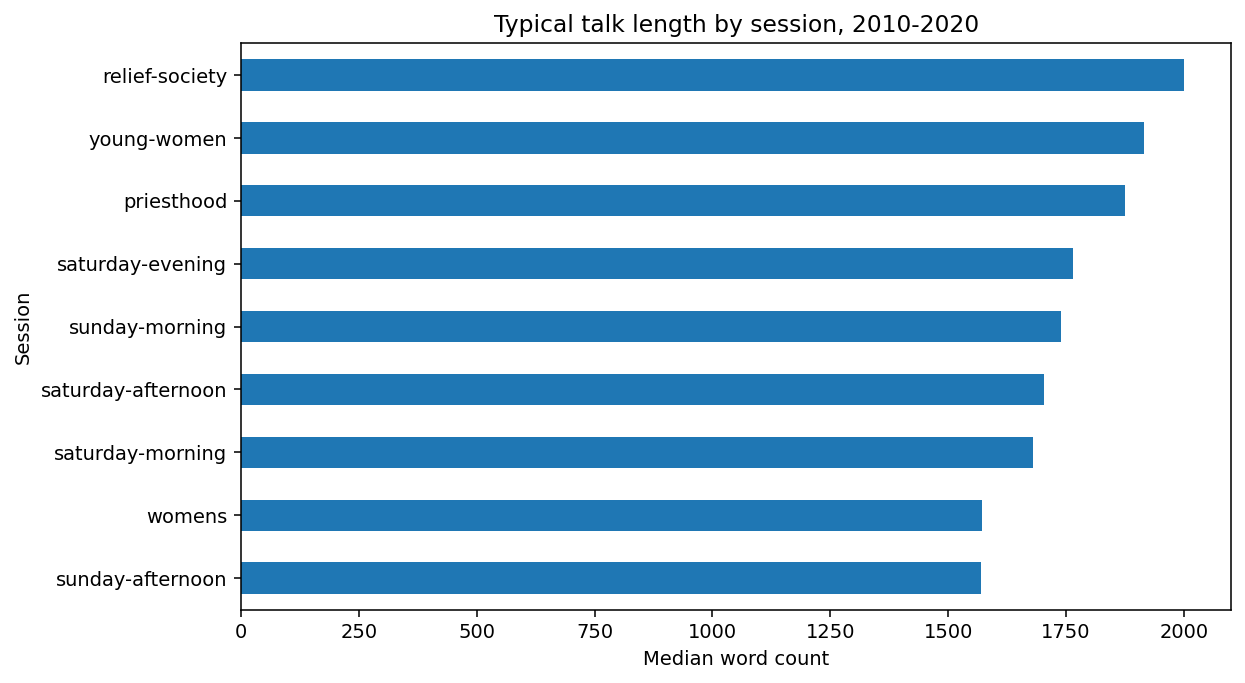

In [20]:
ax = session_summary.sort_values("median_words").plot.barh(
    x="session", y="median_words", legend=False, figsize=(9, 5)
)
ax.set_xlabel("Median word count")
ax.set_ylabel("Session")
ax.set_title("Typical talk length by session, 2010-2020")
plt.tight_layout()
plt.show()



### A bar chart of counts



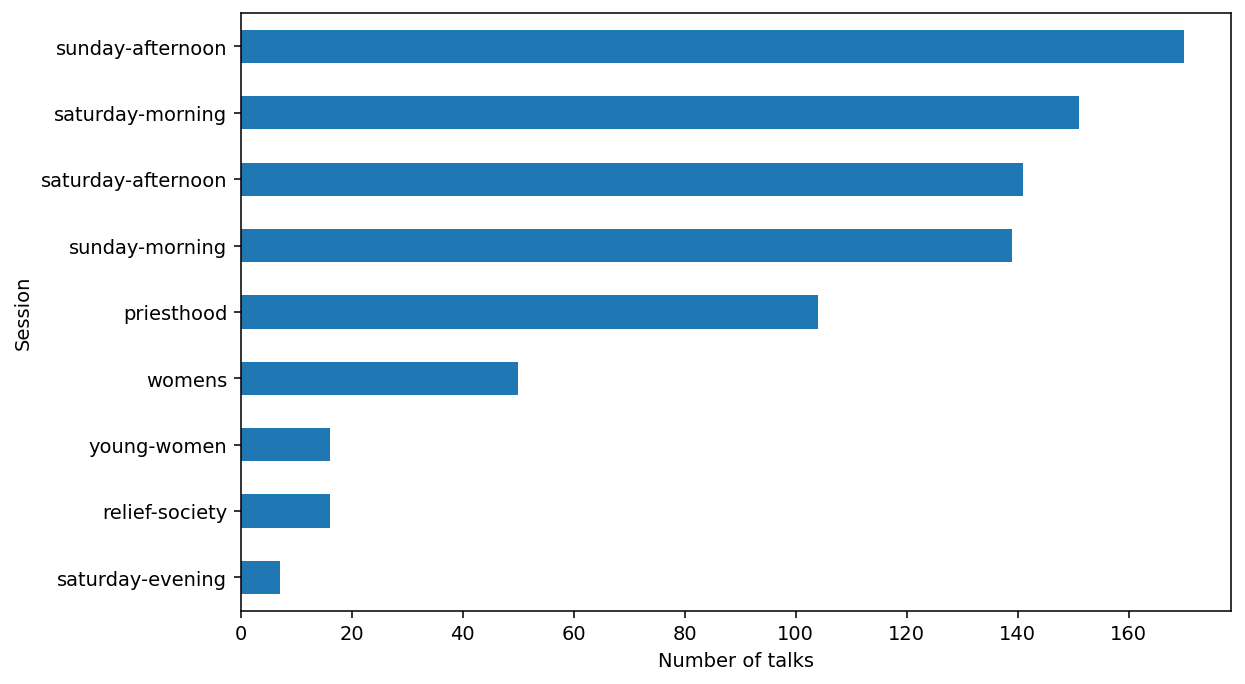

In [21]:
ax = session_counts.sort_values().plot.barh(figsize=(9, 5))
ax.set_xlabel("Number of talks")
ax.set_ylabel("Session")
plt.tight_layout()
plt.show()



### A line chart over time



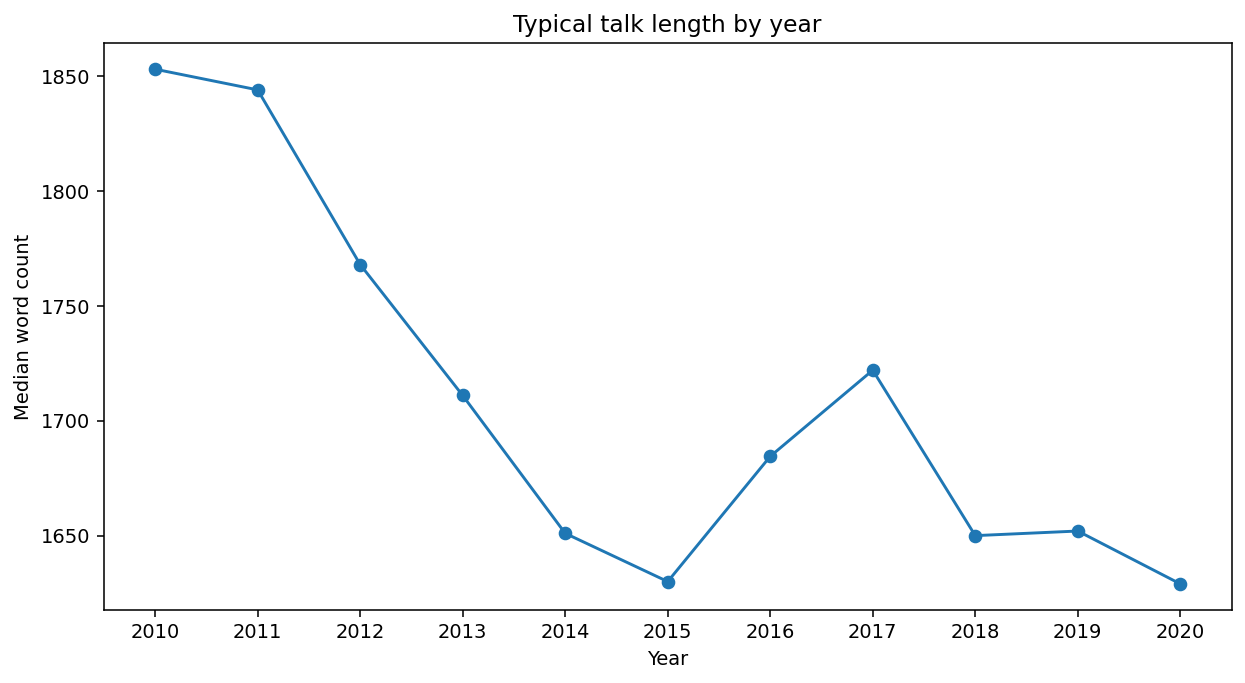

In [22]:
ax = annual.plot.line(
    x="talk_year", y="median_words", marker="o", legend=False,
    figsize=(9, 5)
)
ax.set_xlabel("Year")
ax.set_ylabel("Median word count")
ax.set_title("Typical talk length by year")
ax.set_xticks(annual["talk_year"])
plt.tight_layout()
plt.show()



### A histogram of individual talk lengths



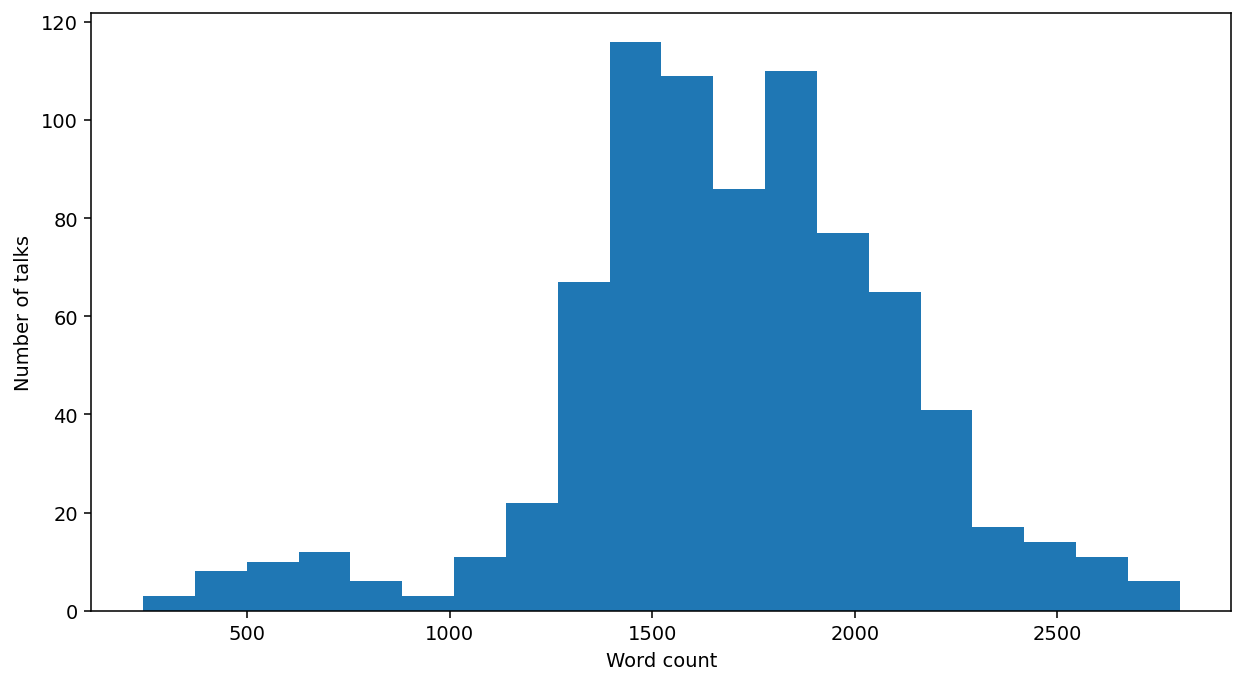

In [23]:
ax = talks["num_words"].plot.hist(bins=20, figsize=(9, 5))
ax.set_xlabel("Word count")
ax.set_ylabel("Number of talks")
plt.tight_layout()
plt.show()



A categorical bar represents a session. A line-chart point represents a year.
A histogram bar counts talks whose word counts fall in a numeric interval.

## Checkpoint 6: Final request

For recorded talks from 2018 through 2020:

1. Compare median word counts across session categories and report counts.
2. Retain categories with at least ten talks and order by median word count.
3. Make a bar chart of that summary.
4. Identify talks in the retained categories that exceed their own session's
   median **calculated from the 2018-2020 talks**.
5. Write one interpretation and one limitation.

### Select the reference observations



In [24]:
recent = talks.loc[talks["year"].between(2018, 2020)].copy()
len(recent)

201



### Summarize, filter groups, and order



In [25]:
recent_summary = recent.groupby("session", as_index=False).agg(
    n_talks=("num_words", "size"),
    median_words=("num_words", "median"),
)

eligible = (
    recent_summary.loc[recent_summary["n_talks"] >= 10]
    .sort_values("median_words", ascending=False)
)
eligible

,session,n_talks,median_words
5,sunday-morning,37,1790.0
3,saturday-morning,41,1728.0
1,saturday-afternoon,39,1629.0
4,sunday-afternoon,46,1621.0
0,priesthood,13,1554.0
6,womens,18,1480.5




There are 201 recent talks, seven observed session categories, and six categories
that meet the ten-talk condition. Seven Saturday evening talks fall outside the
retained categories, leaving 194 talks in eligible categories.

### Plot the group summary



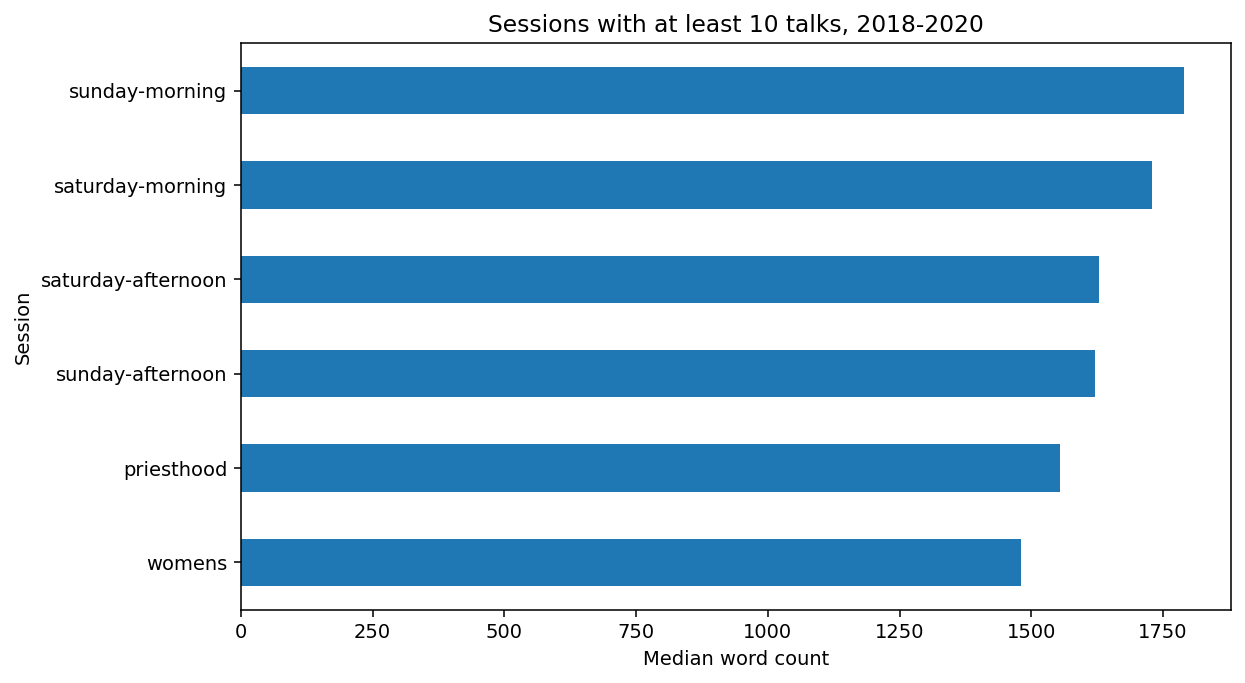

In [26]:
ax = eligible.sort_values("median_words").plot.barh(
    x="session", y="median_words", legend=False, figsize=(9, 5)
)
ax.set_xlabel("Median word count")
ax.set_ylabel("Session")
ax.set_title("Sessions with at least 10 talks, 2018-2020")
plt.tight_layout()
plt.show()



### Attach references and identify qualifying talks



In [27]:
recent["session_median_words"] = (
    recent.groupby("session")["num_words"].transform("median")
)

above_mask = (
    recent["session"].isin(eligible["session"])
    & (recent["num_words"] > recent["session_median_words"])
)

above_recent = recent.loc[
    above_mask,
    ["talk_name", "speaker", "session", "year", "num_words",
     "session_median_words"],
].sort_values(["session", "num_words"], ascending=[True, False])

len(above_recent), above_recent.head()

95

,talk_name,speaker,session,year,num_words,session_median_words
701,Inspired Ministering,Henry B. Eyring,priesthood,2018,2217,1554.0
377,Your Priesthood Playbook,Gary E. Stevenson,priesthood,2019,2202,1554.0
649,The Powers of the Priesthood,Dallin H. Oaks,priesthood,2018,1894,1554.0
386,Behold! A Royal Army,Ronald A. Rasband,priesthood,2018,1676,1554.0
477,The Elders Quorum,D. Todd Christofferson,priesthood,2018,1660,1554.0




### Check the answer



In [28]:
checks = {
    "201_recent_talks": len(recent) == 201,
    "all_groups_accounted_for": recent_summary["n_talks"].sum() == len(recent),
    "six_eligible_sessions": len(eligible) == 6,
    "all_eligible_counts": eligible["n_talks"].ge(10).all(),
    "194_talks_in_eligible_sessions": eligible["n_talks"].sum() == 194,
    "95_above_median_talks": len(above_recent) == 95,
    "allowed_years": above_recent["year"].between(2018, 2020).all(),
    "eligible_sessions": above_recent["session"].isin(eligible["session"]).all(),
    "strictly_above_reference": above_recent["num_words"].gt(
        above_recent["session_median_words"]
    ).all(),
    "dates_match_supplied_years": talks["talk_year"].eq(talks["year"]).all(),
}
checks

{'201_recent_talks': True, 'all_groups_accounted_for': np.True_, 'six_eligible_sessions': True, 'all_eligible_counts': np.True_, '194_talks_in_eligible_sessions': np.True_, '95_above_median_talks': True, 'allowed_years': np.True_, 'eligible_sessions': np.True_, 'strictly_above_reference': np.True_, 'dates_match_supplied_years': np.True_}



### Interpretation and limitation

Among session categories with at least ten recorded talks from 2018 through
2020, Sunday morning has the largest median word count, at 1,790 words.

This descriptive comparison does not establish that the session causes longer
talks. Categories contain different sets of speakers and conference contexts.

## Reflection

- The year filter defines which observations contribute to the statistics.
- Aggregation changes the unit from talk to session category.
- The group-size filter selects summary rows.
- Transformation returns the group reference to each talk.
- The final mask selects individual talks using their reference and membership.
- The summary table supplies the inputs for the bar chart.
